# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

- **Họ và tên:** Nguyễn Phương Nguyên
- **MSSV:** 24521196
- **Lớp:** DS201.R11.1

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp &lt;MSSV&gt;.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này trên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

In [1]:
import os
import sys
import zipfile

# Tự động tải và chuẩn bị thư mục cnn_project nếu chạy trên Google Colab
if not os.path.exists('cnn_project'):
    if os.path.exists('cnn_project.zip'):
        with zipfile.ZipFile('cnn_project.zip', 'r') as z:
            z.extractall('.')
    else:
        print('[INFO] Đang chạy trên Google Colab. Đang tự động tải source code từ GitHub...')
        os.system('git clone https://github.com/nphuongnguyen3107-sys/DS201_Lab2.git /content/DS201_Lab2_temp')
        if os.path.exists('/content/DS201_Lab2_temp/cnn_project'):
            import shutil
            shutil.copytree('/content/DS201_Lab2_temp/cnn_project', 'cnn_project', dirs_exist_ok=True)
            print('[OK] Đã tải thư mục cnn_project thành công!')
for p in ['cnn_project', '.', '..']:
    if os.path.exists(p) and os.path.abspath(p) not in sys.path:
        sys.path.append(os.path.abspath(p))

import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

from data import build_transforms, build_train_val_loaders, build_test_loader
from engine import train_one_epoch, evaluate
from model import (
    LeNet5,
    InceptionBlock, GoogLeNetReduced,
    BasicBlock, ResNet18,
    PretrainedResnet,
    n_params
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print('Imported modules from cnn_project successfully!')


[INFO] Đang chạy trên Google Colab. Đang tự động tải source code từ GitHub...
[OK] Đã tải thư mục cnn_project thành công!
Device: cuda
GPU: Tesla T4
Imported modules from cnn_project successfully!


In [2]:
DATA_ROOT = 'VinaFood21'

# Tự động tải và giải nén dữ liệu VinaFood21 nếu chưa có
if not os.path.exists(DATA_ROOT):
    if not os.path.exists('VinaFood21.zip'):
        print('Downloading VinaFood21 dataset...')
        os.system('pip install -q gdown && gdown --fuzzy 1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR -O VinaFood21.zip')
    if os.path.exists('VinaFood21.zip'):
        print('Extracting VinaFood21.zip...')
        with zipfile.ZipFile('VinaFood21.zip', 'r') as z:
            z.extractall('.')


def train_network(model, train_loader, val_loader, criterion, optimizer, epochs, device, model_name="model"):
    history = []
    best_f1 = -1.0
    start_time = time.time()

    os.makedirs("outputs", exist_ok=True)
    ckpt_path = f"outputs/{model_name}_best.pt"

    print(f"=== Training {model_name} ({epochs} epochs) ===")
    for ep in range(1, epochs + 1):
        ep_start = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, va_f1, _, _ = evaluate(model, val_loader, criterion, device)
        ep_time = time.time() - ep_start

        history.append({
            "epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
            "val_loss": va_loss, "val_acc": va_acc, "val_f1": va_f1,
            "time": ep_time
        })

        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save(model.state_dict(), ckpt_path)
            mark = " [BEST CHECKPOINT]"

        print(f"Epoch {ep:2d}/{epochs:2d} | Train: Loss {tr_loss:.4f} Acc {tr_acc:.4f} | "
              f"Val: Loss {va_loss:.4f} Acc {va_acc:.4f} F1 {va_f1:.4f} ({ep_time:.1f}s){mark}")

    total_time = time.time() - start_time
    avg_ep_time = total_time / epochs
    print(f"--> Completed {model_name} in {total_time/60:.2f}m (~{avg_ep_time:.2f}s/epoch). Best Val F1: {best_f1:.4f}")

    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=device))

    return history, avg_ep_time

# Hàm vẽ biểu đồ Loss
def plot_loss_curves(history, title="Loss Curve", save_name=None):
    epochs = [h["epoch"] for h in history]
    tr_loss = [h["train_loss"] for h in history]
    va_loss = [h["val_loss"] for h in history]

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, tr_loss, label="Train Loss", color="royalblue", lw=2)
    plt.plot(epochs, va_loss, label="Val Loss", color="crimson", lw=2, linestyle="--")
    plt.title(title, fontsize=12, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend()
    if save_name:
        plt.savefig(f"outputs/{save_name}.png", dpi=120, bbox_inches="tight")
    plt.show()

# Hàm vẽ ma trận nhầm lẫn
def plot_confusion_matrix_custom(y_true, y_pred, classes, title="Confusion Matrix", save_name=None):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.title(title, fontsize=12, fontweight="bold")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    if save_name:
        plt.savefig(f"outputs/{save_name}.png", dpi=120, bbox_inches="tight")
    plt.show()

# Hàm in 4 độ đo yêu cầu
def compute_model_metrics(y_true, y_pred, classes):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f} (macro)")
    print(f"Recall    : {rec:.4f} (macro)")
    print(f"Macro-F1  : {f1:.4f}")
    print("\n--- Classification Report ---")
    print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))
    return acc, prec, rec, f1

Extracting VinaFood21.zip...


### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

![image.png](attachment:image.png)

In [3]:
lenet_model = LeNet5(in_ch=3, img_size=64, num_classes=21, pool="avg")
dummy_x = torch.rand(2, 3, 64, 64)
dummy_out = lenet_model(dummy_x)

print(f"Input shape : {tuple(dummy_x.shape)}")
print(f"Output shape: {tuple(dummy_out.shape)}")
print(f"Total params LeNet-5: {n_params(lenet_model):,}")
assert n_params(lenet_model) == 339421, f"Sai số tham số! Thực tế: {n_params(lenet_model)}"
print("--> Matches exactly 339,421 parameters as expected!")

Input shape : (2, 3, 64, 64)
Output shape: (2, 21)
Total params LeNet-5: 339,421
--> Matches exactly 339,421 parameters as expected!


=== Training lenet_avg (20 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train: Loss 2.8375 Acc 0.1406 | Val: Loss 2.7178 Acc 0.1693 F1 0.0887 (113.5s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train: Loss 2.6194 Acc 0.2025 | Val: Loss 2.5566 Acc 0.2032 F1 0.1381 (100.8s) [BEST CHECKPOINT]


...

Epoch 18/20 | Train: Loss 0.0878 Acc 0.9707 | Val: Loss 7.0976 Acc 0.3317 F1 0.3150 (100.1s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train: Loss 0.0973 Acc 0.9694 | Val: Loss 7.0946 Acc 0.3267 F1 0.3153 (100.5s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train: Loss 0.0993 Acc 0.9689 | Val: Loss 7.7399 Acc 0.3207 F1 0.3164 (100.4s)
--> Completed lenet_avg in 33.63m (~100.88s/epoch). Best Val F1: 0.3333

=== TEST EVALUATION: LENET-5 (AvgPool) ===
Accuracy  : 0.2710
Precision : 0.2682 (macro)
Recall    : 0.2621 (macro)
Macro-F1  : 0.2581

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.1779    0.1203    0.1436       241
        banh-hoi     0.3310    0.3097    0.3200       607
    banh-mi-chao     0.2201    0.2042    0.2118       289
        banh-tet     0.4122    0.1676    0.2383       364
 banh-trang-tron     0.2081    0.1003    0.1354       309
          banh-u     0.2087    0.1364    0.1649       176
        banh-uot     0.2513    0.3375    0.2881       560
       bap-nuong     0.1778    0.1119    0.1373       143
          bo-kho     0.2327    0.1893    0.2088       338
       bo-la-lot     0.4317    0.4279    0.4298       458
       bot-chien     0.1754  

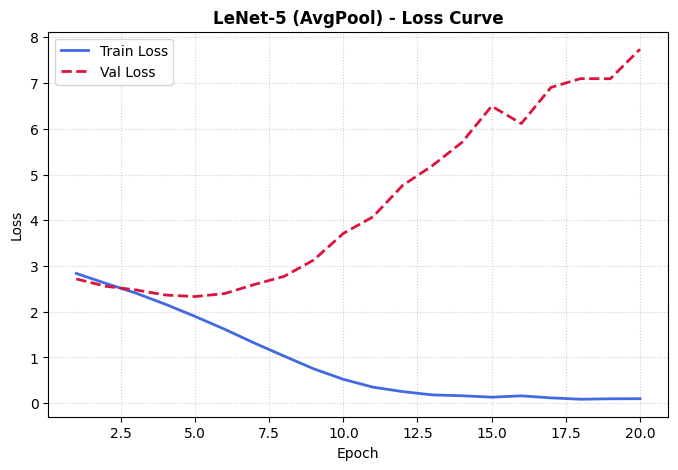

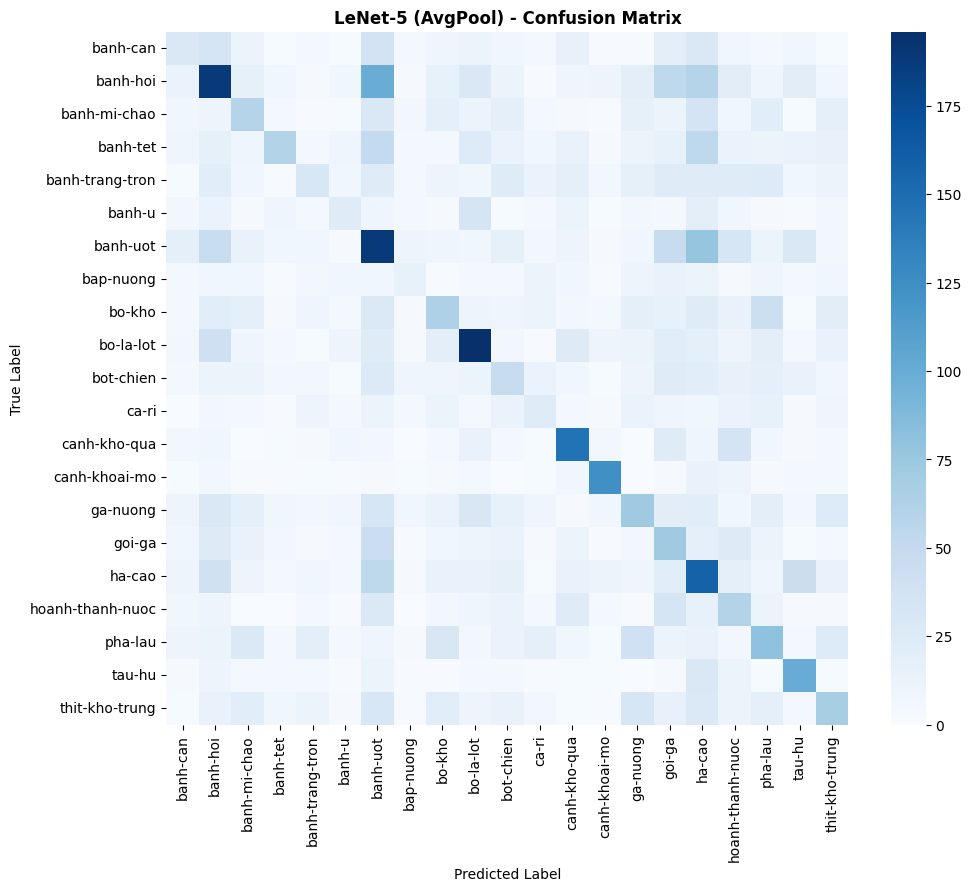

In [4]:
train_loader_64, val_loader_64, classes = build_train_val_loaders(
    data_root=DATA_ROOT, img_size=64, batch_size=32, augment=False, num_workers=2
)
test_loader_64, _ = build_test_loader(
    data_root=DATA_ROOT, img_size=64, batch_size=32, num_workers=2
)

# Huấn luyện bản AvgPool
lenet_avg = LeNet5(in_ch=3, img_size=64, num_classes=len(classes) if classes else 21, pool="avg").to(device)
criterion = nn.CrossEntropyLoss()
optimizer_avg = torch.optim.Adam(lenet_avg.parameters(), lr=1e-3)

if train_loader_64 is not None:
    history_lenet_avg, time_lenet_avg = train_network(
        lenet_avg, train_loader_64, val_loader_64, criterion, optimizer_avg,
        epochs=20, device=device, model_name="lenet_avg"
    )

    print("\n=== TEST EVALUATION: LENET-5 (AvgPool) ===")
    _, _, _, y_true_avg, y_pred_avg = evaluate(lenet_avg, test_loader_64, criterion, device)
    lenet_avg_acc, lenet_avg_prec, lenet_avg_rec, lenet_avg_f1 = compute_model_metrics(y_true_avg, y_pred_avg, classes)

    plot_loss_curves(history_lenet_avg, title="LeNet-5 (AvgPool) - Loss Curve", save_name="loss_curve_lenet_avg")
    plot_confusion_matrix_custom(y_true_avg, y_pred_avg, classes, title="LeNet-5 (AvgPool) - Confusion Matrix", save_name="confusion_matrix_lenet_avg")

In [5]:
# Huấn luyện bản MaxPool để so sánh
lenet_max = LeNet5(in_ch=3, img_size=64, num_classes=len(classes) if classes else 21, pool="max").to(device)
optimizer_max = torch.optim.Adam(lenet_max.parameters(), lr=1e-3)

if train_loader_64 is not None:
    history_lenet_max, time_lenet_max = train_network(
        lenet_max, train_loader_64, val_loader_64, criterion, optimizer_max,
        epochs=20, device=device, model_name="lenet_max"
    )

    print("\n=== TEST EVALUATION: LENET-5 (MaxPool) ===")
    _, _, _, y_true_max, y_pred_max = evaluate(lenet_max, test_loader_64, criterion, device)
    lenet_max_acc, lenet_max_prec, lenet_max_rec, lenet_max_f1 = compute_model_metrics(y_true_max, y_pred_max, classes)

    print(f"\n--> Macro-F1 Comparison: AvgPool ({lenet_avg_f1:.4f}) vs MaxPool ({lenet_max_f1:.4f})")

=== Training lenet_max (20 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train: Loss 2.8033 Acc 0.1490 | Val: Loss 2.6411 Acc 0.1733 F1 0.1006 (109.9s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train: Loss 2.5609 Acc 0.2153 | Val: Loss 2.4857 Acc 0.2171 F1 0.1485 (102.5s) [BEST CHECKPOINT]


...

Epoch 18/20 | Train: Loss 0.1763 Acc 0.9416 | Val: Loss 6.0285 Acc 0.3257 F1 0.3043 (100.3s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train: Loss 0.1555 Acc 0.9531 | Val: Loss 6.3336 Acc 0.3167 F1 0.2971 (99.5s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train: Loss 0.1565 Acc 0.9487 | Val: Loss 6.4710 Acc 0.3207 F1 0.2982 (99.6s)
--> Completed lenet_max in 33.51m (~100.54s/epoch). Best Val F1: 0.3157

=== TEST EVALUATION: LENET-5 (MaxPool) ===
Accuracy  : 0.2628
Precision : 0.2539 (macro)
Recall    : 0.2582 (macro)
Macro-F1  : 0.2376

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.1500    0.0373    0.0598       241
        banh-hoi     0.3629    0.2224    0.2758       607
    banh-mi-chao     0.2459    0.3114    0.2748       289
        banh-tet     0.3028    0.1813    0.2268       364
 banh-trang-tron     0.1638    0.0615    0.0894       309
          banh-u     0.1818    0.0341    0.0574       176
        banh-uot     0.2669    0.2464    0.2563       560
       bap-nuong     0.1084    0.1538    0.1272       143
          bo-kho     0.2664    0.2160    0.2386       338
       bo-la-lot     0.4298    0.5284    0.4740       458
       bot-chien     0.1459   

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

![image.png](attachment:image.png)

**GoogLeNet (Multi-branch Network)**

![image-2.png](attachment:image-2.png)

In [6]:
# Kiểm định 2 InceptionBlock mẫu theo tài liệu đề bài
b1 = InceptionBlock(1, 16, 16, 24, 4, 8, 8)
p1 = n_params(b1)
print(f"Block 1 (1 ch in -> 56 ch out)  : {p1:,} params (Expected: 4,376)")
assert p1 == 4376

b2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
p2 = n_params(b2)
print(f"Block 2 (56 ch in -> 112 ch out): {p2:,} params (Expected: 22,104)")
assert p2 == 22104

# Khởi tạo mô hình GoogLeNet rút gọn
model_gn = GoogLeNetReduced(num_classes=21)
print(f"\nTotal params GoogLeNet Reduced: {n_params(model_gn):,}")

Block 1 (1 ch in -> 56 ch out)  : 4,376 params (Expected: 4,376)
Block 2 (56 ch in -> 112 ch out): 22,104 params (Expected: 22,104)

Total params GoogLeNet Reduced: 414,709


=== Training googlenet (20 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train: Loss 2.8875 Acc 0.1094 | Val: Loss 2.6766 Acc 0.1624 F1 0.0863 (102.5s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train: Loss 2.6524 Acc 0.1764 | Val: Loss 2.4804 Acc 0.2281 F1 0.1504 (103.0s) [BEST CHECKPOINT]


...

Epoch 18/20 | Train: Loss 1.4279 Acc 0.5462 | Val: Loss 1.5558 Acc 0.5249 F1 0.4927 (102.3s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train: Loss 1.3696 Acc 0.5685 | Val: Loss 1.5711 Acc 0.5209 F1 0.4902 (103.4s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train: Loss 1.3250 Acc 0.5782 | Val: Loss 1.5369 Acc 0.5359 F1 0.4909 (101.8s)
--> Completed googlenet in 34.71m (~104.14s/epoch). Best Val F1: 0.4927

=== TEST EVALUATION: GOOGLENET REDUCED ===
Accuracy  : 0.4439
Precision : 0.4482 (macro)
Recall    : 0.4456 (macro)
Macro-F1  : 0.4281

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.2811    0.4689    0.3515       241
        banh-hoi     0.5837    0.4827    0.5284       607
    banh-mi-chao     0.4489    0.5017    0.4739       289
        banh-tet     0.5923    0.4670    0.5223       364
 banh-trang-tron     0.3584    0.2006    0.2573       309
          banh-u     0.3889    0.3182    0.3500       176
        banh-uot     0.5469    0.2393    0.3329       560
       bap-nuong     0.3297    0.2098    0.2564       143
          bo-kho     0.4246    0.5828    0.4913       338
       bo-la-lot     0.4745    0.8515    0.6094       458
       bot-chien     0.2908  

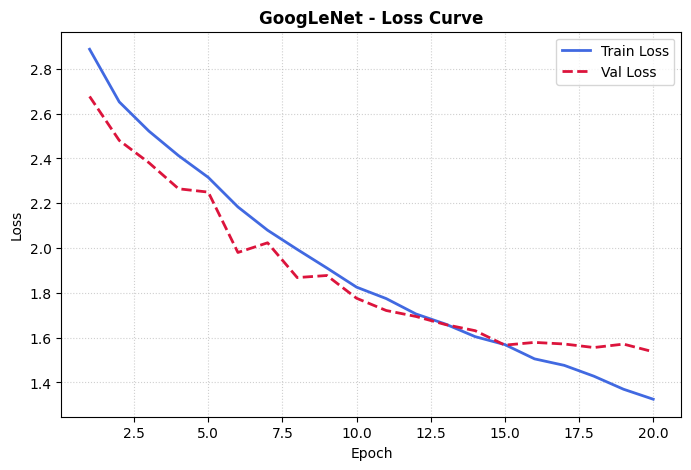

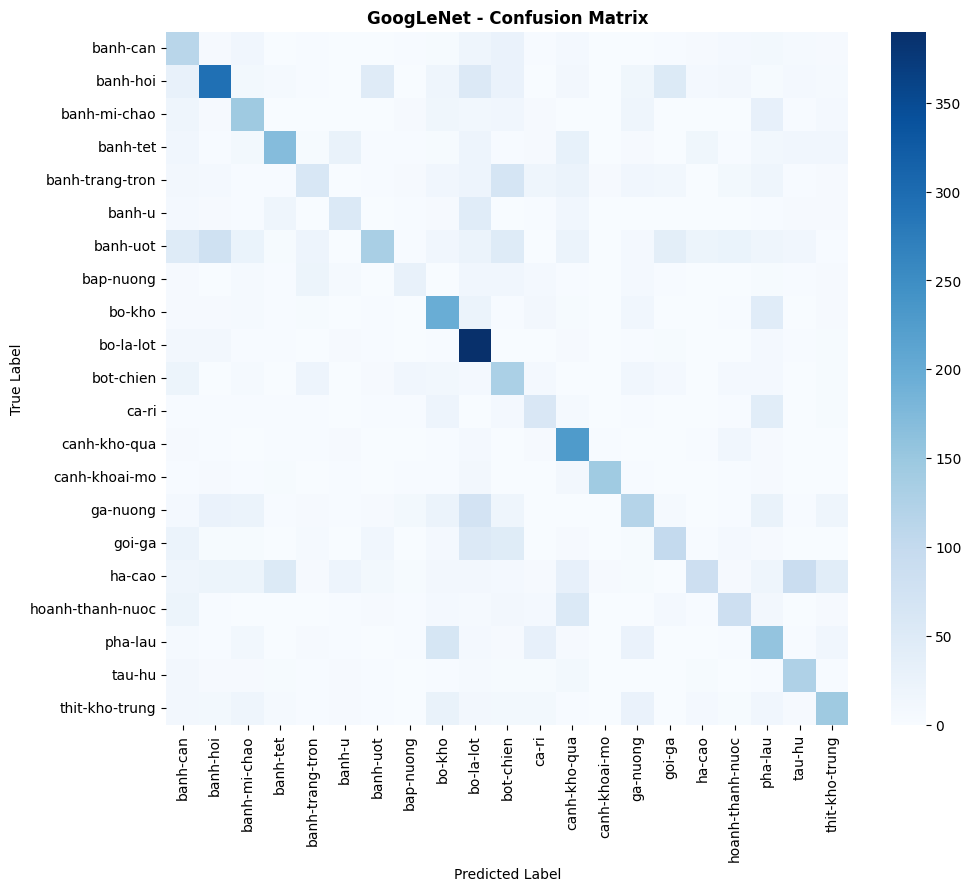

In [7]:
googlenet = GoogLeNetReduced(num_classes=len(classes) if classes else 21).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_gn = torch.optim.Adam(googlenet.parameters(), lr=1e-3)

if train_loader_64 is not None:
    history_gn, time_gn = train_network(
        googlenet, train_loader_64, val_loader_64, criterion, optimizer_gn,
        epochs=20, device=device, model_name="googlenet"
    )

    print("\n=== TEST EVALUATION: GOOGLENET REDUCED ===")
    _, _, _, y_true_gn, y_pred_gn = evaluate(googlenet, test_loader_64, criterion, device)
    gn_acc, gn_prec, gn_rec, gn_f1 = compute_model_metrics(y_true_gn, y_pred_gn, classes)

    plot_loss_curves(history_gn, title="GoogLeNet - Loss Curve", save_name="loss_curve_googlenet")
    plot_confusion_matrix_custom(y_true_gn, y_pred_gn, classes, title="GoogLeNet - Confusion Matrix", save_name="confusion_matrix_googlenet")

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

![image.png](attachment:image.png)

**ResNet**

![image-2.png](attachment:image-2.png)

In [8]:
# Khởi tạo và kiểm tra số tham số ResNet-18
r18_model = ResNet18(num_classes=21)
print(f"Total params ResNet-18: {n_params(r18_model):,} (Expected: 11,187,285)")
assert n_params(r18_model) == 11187285, f"Sai số tham số! Thực tế: {n_params(r18_model)}"
print("--> Matches exactly 11,187,285 parameters as expected!")

Total params ResNet-18: 11,187,285 (Expected: 11,187,285)
--> Matches exactly 11,187,285 parameters as expected!


In [9]:
# Nạp dữ liệu 96x96 KHÔNG augment
train_dl_no_aug, val_dl_no_aug, _ = build_train_val_loaders(
    data_root=DATA_ROOT, img_size=96, batch_size=32, augment=False, num_workers=2
)
test_dl_96, _ = build_test_loader(data_root=DATA_ROOT, img_size=96, batch_size=32, num_workers=2)

r18_no_aug = ResNet18(num_classes=len(classes) if classes else 21).to(device)
opt_no_aug = torch.optim.Adam(r18_no_aug.parameters(), lr=1e-3)

if train_dl_no_aug is not None:
    history_r18_no_aug, time_r18_no_aug = train_network(
        r18_no_aug, train_dl_no_aug, val_dl_no_aug, nn.CrossEntropyLoss(), opt_no_aug,
        epochs=20, device=device, model_name="r18_no_aug"
    )

    print("\n=== TEST EVALUATION: RESNET-18 (NO AUGMENT) ===")
    _, _, _, y_true_r18_no, y_pred_r18_no = evaluate(r18_no_aug, test_dl_96, nn.CrossEntropyLoss(), device)
    r18_no_acc, r18_no_prec, r18_no_rec, r18_no_f1 = compute_model_metrics(y_true_r18_no, y_pred_r18_no, classes)

=== Training r18_no_aug (20 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train: Loss 2.6768 Acc 0.1959 | Val: Loss 2.5192 Acc 0.2390 F1 0.1703 (104.9s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train: Loss 2.3641 Acc 0.2772 | Val: Loss 2.6954 Acc 0.2321 F1 0.1732 (106.1s) [BEST CHECKPOINT]


...

Epoch 18/20 | Train: Loss 0.0832 Acc 0.9733 | Val: Loss 2.9312 Acc 0.4990 F1 0.4766 (108.1s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train: Loss 0.0933 Acc 0.9715 | Val: Loss 3.1494 Acc 0.4980 F1 0.4744 (105.8s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train: Loss 0.1071 Acc 0.9636 | Val: Loss 2.8669 Acc 0.5030 F1 0.4780 (105.4s)
--> Completed r18_no_aug in 35.51m (~106.52s/epoch). Best Val F1: 0.4940

=== TEST EVALUATION: RESNET-18 (NO AUGMENT) ===
Accuracy  : 0.3969
Precision : 0.4160 (macro)
Recall    : 0.3993 (macro)
Macro-F1  : 0.3925

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.3947    0.1245    0.1893       241
        banh-hoi     0.6156    0.3773    0.4678       607
    banh-mi-chao     0.3741    0.5190    0.4348       289
        banh-tet     0.5889    0.2912    0.3897       364
 banh-trang-tron     0.2590    0.2557    0.2573       309
          banh-u     0.3350    0.3750    0.3539       176
        banh-uot     0.3896    0.3214    0.3523       560
       bap-nuong     0.2500    0.2517    0.2509       143
          bo-kho     0.2791    0.5533    0.3710       338
       bo-la-lot     0.6269    0.5502    0.5860       458
       bot-chien     0.

In [10]:
# Nạp dữ liệu 96x96 CÓ augment (RandomCrop, Flip, Rotation, ColorJitter)
train_dl_aug, val_dl_aug, _ = build_train_val_loaders(
    data_root=DATA_ROOT, img_size=96, batch_size=32, augment=True, num_workers=2
)

r18_aug = ResNet18(num_classes=len(classes) if classes else 21).to(device)
opt_aug = torch.optim.Adam(r18_aug.parameters(), lr=1e-3)

if train_dl_aug is not None:
    history_r18_aug, time_r18_aug = train_network(
        r18_aug, train_dl_aug, val_dl_aug, nn.CrossEntropyLoss(), opt_aug,
        epochs=20, device=device, model_name="r18_aug"
    )

    print("\n=== TEST EVALUATION: RESNET-18 (WITH AUGMENT) ===")
    _, _, _, y_true_r18_aug, y_pred_r18_aug = evaluate(r18_aug, test_dl_96, nn.CrossEntropyLoss(), device)
    r18_aug_acc, r18_aug_prec, r18_aug_rec, r18_aug_f1 = compute_model_metrics(y_true_r18_aug, y_pred_r18_aug, classes)

=== Training r18_aug (20 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/20 | Train: Loss 2.7658 Acc 0.1742 | Val: Loss 2.6761 Acc 0.1793 F1 0.1337 (119.1s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  2/20 | Train: Loss 2.4898 Acc 0.2399 | Val: Loss 2.5181 Acc 0.2520 F1 0.1823 (118.4s) [BEST CHECKPOINT]


...

Epoch 18/20 | Train: Loss 1.1783 Acc 0.6219 | Val: Loss 1.5566 Acc 0.5418 F1 0.5110 (113.4s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | Train: Loss 1.1206 Acc 0.6334 | Val: Loss 1.4253 Acc 0.5717 F1 0.5348 (112.5s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | Train: Loss 1.0816 Acc 0.6499 | Val: Loss 1.4833 Acc 0.5528 F1 0.5290 (114.7s)
--> Completed r18_aug in 38.65m (~115.96s/epoch). Best Val F1: 0.5348

=== TEST EVALUATION: RESNET-18 (WITH AUGMENT) ===
Accuracy  : 0.4949
Precision : 0.4957 (macro)
Recall    : 0.4786 (macro)
Macro-F1  : 0.4758

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.3846    0.4564    0.4175       241
        banh-hoi     0.6189    0.4975    0.5516       607
    banh-mi-chao     0.5661    0.5779    0.5719       289
        banh-tet     0.5802    0.5165    0.5465       364
 banh-trang-tron     0.4167    0.3560    0.3839       309
          banh-u     0.5465    0.2670    0.3588       176
        banh-uot     0.3914    0.5375    0.4530       560
       bap-nuong     0.3097    0.3357    0.3221       143
          bo-kho     0.4748    0.5296    0.5007       338
       bo-la-lot     0.6710    0.6812    0.6761       458
       bot-chien     0.2

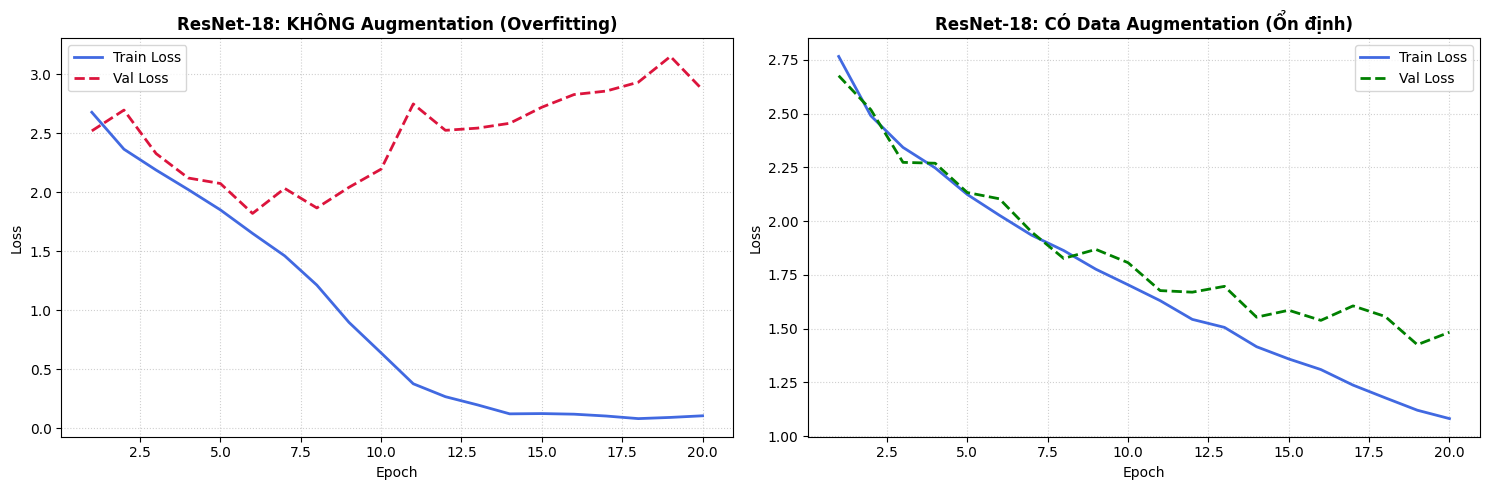

--> Macro-F1 difference between runs: +0.0833


In [11]:
# Vẽ đồ thị so sánh trực quan hiện tượng Overfitting giữa 2 lần chạy
if train_dl_no_aug is not None and train_dl_aug is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 1. Không có Augmentation
    ep_no = [h["epoch"] for h in history_r18_no_aug]
    axes[0].plot(ep_no, [h["train_loss"] for h in history_r18_no_aug], label="Train Loss", color="royalblue", lw=2)
    axes[0].plot(ep_no, [h["val_loss"] for h in history_r18_no_aug], label="Val Loss", color="crimson", lw=2, linestyle="--")
    axes[0].set_title("ResNet-18: KHÔNG Augmentation (Overfitting)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].grid(True, linestyle=":", alpha=0.6); axes[0].legend()

    # 2. Có Augmentation
    ep_aug = [h["epoch"] for h in history_r18_aug]
    axes[1].plot(ep_aug, [h["train_loss"] for h in history_r18_aug], label="Train Loss", color="royalblue", lw=2)
    axes[1].plot(ep_aug, [h["val_loss"] for h in history_r18_aug], label="Val Loss", color="green", lw=2, linestyle="--")
    axes[1].set_title("ResNet-18: CÓ Data Augmentation (Ổn định)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].grid(True, linestyle=":", alpha=0.6); axes[1].legend()

    plt.tight_layout()
    plt.savefig("outputs/resnet18_overfitting_comparison.png", dpi=120, bbox_inches="tight")
    plt.show()

    print(f"--> Macro-F1 difference between runs: {r18_aug_f1 - r18_no_f1:+.4f}")

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

In [12]:
# Kiểm tra số tham số học được ở 2 chế độ
m_fe = PretrainedResnet(num_classes=21, freeze_backbone=True)
m_ft = PretrainedResnet(num_classes=21, freeze_backbone=False)

p_fe = n_params(m_fe, trainable_only=True)
p_ft = n_params(m_ft, trainable_only=True)
p_total = n_params(m_fe)

print(f"Total params ResNet-50 : {p_total:,} (Expected: 23,551,061)")
print(f"Feature Extraction trainable: {p_fe:,} (Expected: 43,029)")
print(f"Fine-Tuning trainable       : {p_ft:,} (Expected: 23,551,061)")

assert p_fe == 43029, f"Sai số tham số FE! Thực tế: {p_fe}"
assert p_ft == 23551061, f"Sai số tham số FT! Thực tế: {p_ft}"
print("--> PretrainedResnet verified successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Total params ResNet-50 : 23,551,061 (Expected: 23,551,061)
Feature Extraction trainable: 43,029 (Expected: 43,029)
Fine-Tuning trainable       : 23,551,061 (Expected: 23,551,061)
--> PretrainedResnet verified successfully!


In [13]:
# Nạp dữ liệu 224x224
train_dl_224, val_dl_224, _ = build_train_val_loaders(
    data_root=DATA_ROOT, img_size=224, batch_size=32, augment=False, num_workers=2
)
test_dl_224, _ = build_test_loader(data_root=DATA_ROOT, img_size=224, batch_size=32, num_workers=2)

model_fe = PretrainedResnet(num_classes=len(classes) if classes else 21, freeze_backbone=True).to(device)
criterion = nn.CrossEntropyLoss()
# Chỉ đưa các tham số requires_grad=True vào optimizer
optimizer_fe = torch.optim.Adam(filter(lambda p: p.requires_grad, model_fe.parameters()), lr=1e-3)

if train_dl_224 is not None:
    history_fe, time_fe = train_network(
        model_fe, train_dl_224, val_dl_224, criterion, optimizer_fe,
        epochs=10, device=device, model_name="resnet50_fe"
    )

    print("\n=== TEST EVALUATION: RESNET-50 (FEATURE EXTRACTION) ===")
    _, _, _, y_true_fe, y_pred_fe = evaluate(model_fe, test_dl_224, criterion, device)
    fe_acc, fe_prec, fe_rec, fe_f1 = compute_model_metrics(y_true_fe, y_pred_fe, classes)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

=== Training resnet50_fe (10 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/10 | Train: Loss 2.4276 Acc 0.3489 | Val: Loss 2.0080 Acc 0.5020 F1 0.4609 (125.8s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch  8/10 | Train: Loss 0.9883 Acc 0.7290 | Val: Loss 1.1164 Acc 0.6713 F1 0.6676 (125.3s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  9/10 | Train: Loss 0.9273 Acc 0.7558 | Val: Loss 1.0767 Acc 0.6972 F1 0.6989 (124.3s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/10 | Train: Loss 0.8925 Acc 0.7639 | Val: Loss 1.0639 Acc 0.6972 F1 0.6950 (126.0s)
--> Completed resnet50_fe in 20.97m (~125.84s/epoch). Best Val F1: 0.6989

=== TEST EVALUATION: RESNET-50 (FEATURE EXTRACTION) ===
Accuracy  : 0.6236
Precision : 0.6422 (macro)
Recall    : 0.6324 (macro)
Macro-F1  : 0.6312

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.6285    0.6598    0.6437       241
        banh-hoi     0.5542    0.6063    0.5791       607
    banh-mi-chao     0.6390    0.7716    0.6991       289
        banh-tet     0.8534    0.5440    0.6644       364
 banh-trang-tron     0.7585    0.5793    0.6569       309
          banh-u     0.5948    0.7841    0.6765       176
        banh-uot     0.5150    0.4607    0.4863       560
       bap-nuong     0.8209    0.7692    0.7942       143
          bo-kho     0.7004    0.5325    0.6050       338
       bo-la-lot     0.6113    0.6834    0.6454       458
       bot-chi

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

=== Training resnet50_ft (10 epochs) ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  1/10 | Train: Loss 2.6808 Acc 0.2125 | Val: Loss 2.0392 Acc 0.4631 F1 0.3318 (144.8s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch  8/10 | Train: Loss 0.0865 Acc 0.9829 | Val: Loss 0.4228 Acc 0.8705 F1 0.8682 (144.4s) [BEST CHECKPOINT]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch  9/10 | Train: Loss 0.0587 Acc 0.9881 | Val: Loss 0.4244 Acc 0.8705 F1 0.8674 (146.2s)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/10 | Train: Loss 0.0410 Acc 0.9926 | Val: Loss 0.4277 Acc 0.8775 F1 0.8752 (149.8s) [BEST CHECKPOINT]
--> Completed resnet50_ft in 24.33m (~145.99s/epoch). Best Val F1: 0.8752

=== TEST EVALUATION: RESNET-50 (FINE-TUNING) ===
Accuracy  : 0.8295
Precision : 0.8320 (macro)
Recall    : 0.8309 (macro)
Macro-F1  : 0.8297

--- Classification Report ---
                  precision    recall  f1-score   support

        banh-can     0.8231    0.8880    0.8543       241
        banh-hoi     0.8034    0.8682    0.8345       607
    banh-mi-chao     0.8927    0.8927    0.8927       289
        banh-tet     0.9760    0.7830    0.8689       364
 banh-trang-tron     0.9197    0.8155    0.8645       309
          banh-u     0.7772    0.8920    0.8307       176
        banh-uot     0.8090    0.7411    0.7735       560
       bap-nuong     0.9712    0.9441    0.9574       143
          bo-kho     0.7268    0.7870    0.7557       338
       bo-la-lot     0.8569    0.9279    0.8910       458
   

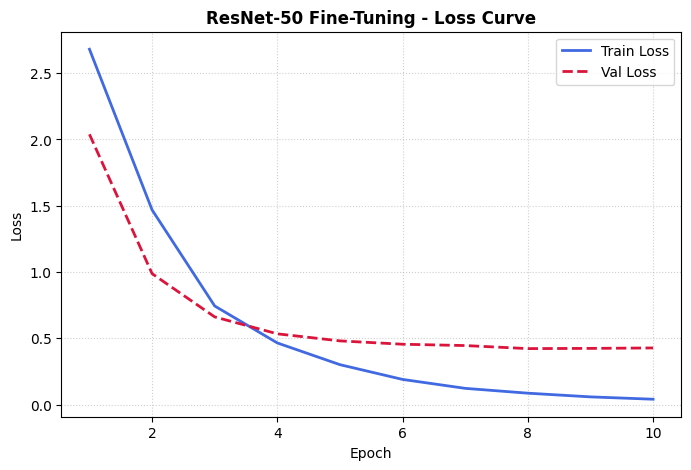

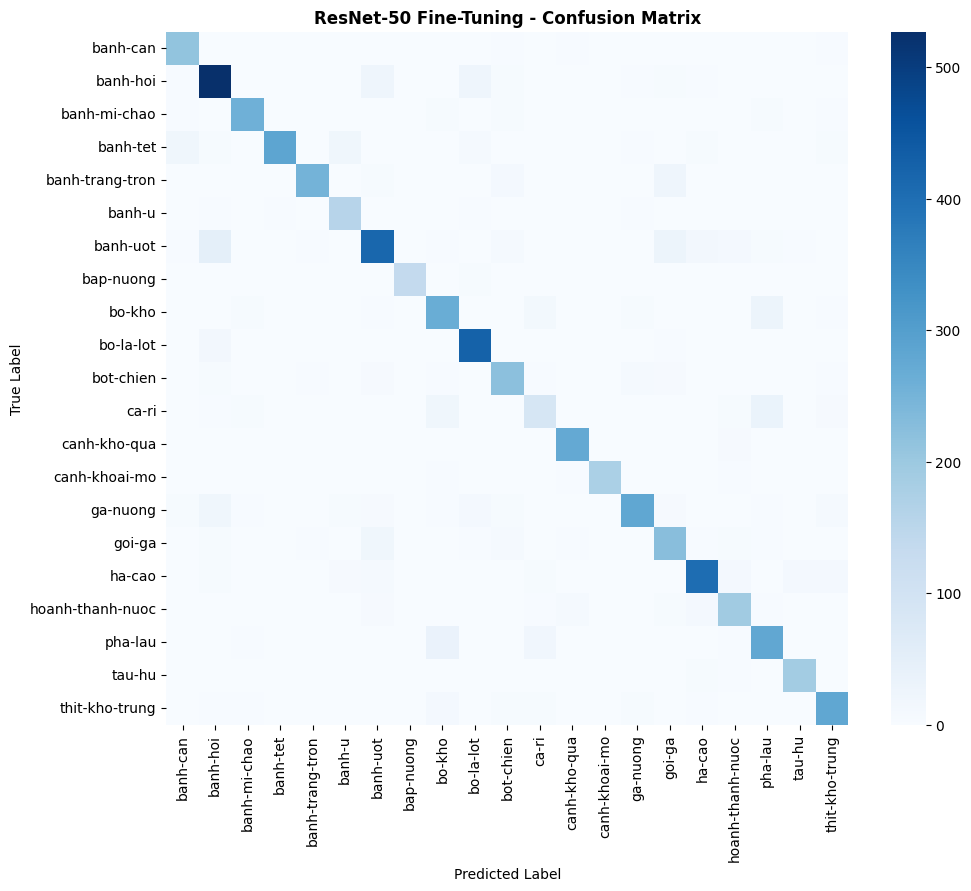

In [14]:
model_ft = PretrainedResnet(num_classes=len(classes) if classes else 21, freeze_backbone=False).to(device)
optimizer_ft = torch.optim.Adam(model_ft.parameters(), lr=1e-4)

if train_dl_224 is not None:
    history_ft, time_ft = train_network(
        model_ft, train_dl_224, val_dl_224, criterion, optimizer_ft,
        epochs=10, device=device, model_name="resnet50_ft"
    )

    print("\n=== TEST EVALUATION: RESNET-50 (FINE-TUNING) ===")
    _, _, _, y_true_ft, y_pred_ft = evaluate(model_ft, test_dl_224, criterion, device)
    ft_acc, ft_prec, ft_rec, ft_f1 = compute_model_metrics(y_true_ft, y_pred_ft, classes)

    plot_loss_curves(history_ft, title="ResNet-50 Fine-Tuning - Loss Curve", save_name="resnet50_loss_curves")
    plot_confusion_matrix_custom(y_true_ft, y_pred_ft, classes, title="ResNet-50 Fine-Tuning - Confusion Matrix", save_name="confusion_matrix_resnet50")

### Bảng Tổng Hợp Kết Quả Các Mô Hình


In [15]:
summary_data = [
    {
        "Mô hình": "LeNet-5 điều chỉnh (AvgPool)",
        "Resize": "64x64",
        "Tham số": "339,421",
        "Giây/epoch": f"{time_lenet_avg:.2f}s" if 'time_lenet_avg' in locals() else "-",
        "Accuracy": f"{lenet_avg_acc:.4f}" if 'lenet_avg_acc' in locals() else "-",
        "macro-F1": f"{lenet_avg_f1:.4f}" if 'lenet_avg_f1' in locals() else "-"
    },
    {
        "Mô hình": "LeNet-5 điều chỉnh (MaxPool)",
        "Resize": "64x64",
        "Tham số": "339,421",
        "Giây/epoch": f"{time_lenet_max:.2f}s" if 'time_lenet_max' in locals() else "-",
        "Accuracy": f"{lenet_max_acc:.4f}" if 'lenet_max_acc' in locals() else "-",
        "macro-F1": f"{lenet_max_f1:.4f}" if 'lenet_max_f1' in locals() else "-"
    },
    {
        "Mô hình": "GoogLeNet rút gọn (4 Inception + GAP)",
        "Resize": "64x64",
        "Tham số": f"{n_params(model_gn):,}" if 'model_gn' in locals() else "414,709",
        "Giây/epoch": f"{time_gn:.2f}s" if 'time_gn' in locals() else "-",
        "Accuracy": f"{gn_acc:.4f}" if 'gn_acc' in locals() else "-",
        "macro-F1": f"{gn_f1:.4f}" if 'gn_f1' in locals() else "-"
    },
    {
        "Mô hình": "ResNet-18 từ đầu (No Augment)*",
        "Resize": "96x96",
        "Tham số": "11,187,285",
        "Giây/epoch": f"{time_r18_no_aug:.2f}s" if 'time_r18_no_aug' in locals() else "-",
        "Accuracy": f"{r18_no_acc:.4f}" if 'r18_no_acc' in locals() else "-",
        "macro-F1": f"{r18_no_f1:.4f}" if 'r18_no_f1' in locals() else "-"
    },
    {
        "Mô hình": "ResNet-18 từ đầu (With Augment)*",
        "Resize": "96x96",
        "Tham số": "11,187,285",
        "Giây/epoch": f"{time_r18_aug:.2f}s" if 'time_r18_aug' in locals() else "-",
        "Accuracy": f"{r18_aug_acc:.4f}" if 'r18_aug_acc' in locals() else "-",
        "macro-F1": f"{r18_aug_f1:.4f}" if 'r18_aug_f1' in locals() else "-"
    },
    {
        "Mô hình": "ResNet-50 Pretrained (Feature Extraction)*",
        "Resize": "224x224",
        "Tham số": "43,029 (h/luyện) / 23.5M",
        "Giây/epoch": f"{time_fe:.2f}s" if 'time_fe' in locals() else "-",
        "Accuracy": f"{fe_acc:.4f}" if 'fe_acc' in locals() else "-",
        "macro-F1": f"{fe_f1:.4f}" if 'fe_f1' in locals() else "-"
    },
    {
        "Mô hình": "ResNet-50 Pretrained (Fine-Tuning)*",
        "Resize": "224x224",
        "Tham số": "23,551,061",
        "Giây/epoch": f"{time_ft:.2f}s" if 'time_ft' in locals() else "-",
        "Accuracy": f"{ft_acc:.4f}" if 'ft_acc' in locals() else "-",
        "macro-F1": f"{ft_f1:.4f}" if 'ft_f1' in locals() else "-"
    }
]

df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Mô hình,Resize,Tham số,Giây/epoch,Accuracy,macro-F1
0,LeNet-5 điều chỉnh (AvgPool),64x64,"339,421",100.88s,0.2710,0.2581
1,LeNet-5 điều chỉnh (MaxPool),64x64,"339,421",100.54s,0.2628,0.2376
2,GoogLeNet rút gọn (4 Inception + GAP),64x64,"414,709",104.14s,0.4439,0.4281
3,ResNet-18 từ đầu (No Augment)*,96x96,"11,187,285",106.52s,0.3969,0.3925
4,ResNet-18 từ đầu (With Augment)*,96x96,"11,187,285",115.96s,0.4949,0.4758
5,ResNet-50 Pretrained (Feature Extraction)*,224x224,"43,029 (h/luyện) / 23.5M",125.84s,0.6236,0.6312
6,ResNet-50 Pretrained (Fine-Tuning)*,224x224,"23,551,061",145.99s,0.8295,0.8297
